# ***Курсовая работа***

# *Построение атрибутов и модели для классификации транзакций*

# 1. Введение

В современном мире банки активно внедряют различные технологии в свою структуру для оптимизации работы и повышения привлекательности для клиентов, однако с их увеличением повышается информационный риск со стороны мошенников. Одним из подобных рисков является произведение мошеннических транзакций, которые нужно отслеживать и пресекать, иначе банк понесет потери как денежные, так и клиентские. Но и здесь все не так просто, ведь среди тысяч обычных, появляется лишь десятки мошеннических.

В данной работе будут рассмотрены различные стратегии для отслеживания как можно большего количества мошеннических транзакций и улучшения качества моделей.

Цель работы: построить оптимальную модель для классификации транзакций.

Задачи работы:

- Построить и продиагностировать первые модели без работы с атрибутами и дисбалансом классов;
- Провести построение атрибутов путем отобра по важности;
- Построить и продиагностировать модели с учетом дисбаланса классов;
- Выделить качественные модели из каждого пункта.

## Импорт библиотек

In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.simplefilter('ignore');
import seaborn as sns

# Для разбиения на обучающие и тестовые выборки
from sklearn.model_selection import train_test_split

# Для кросс-валидации
from sklearn.model_selection import cross_validate, StratifiedKFold

# Методы для оценки качества моделей
from sklearn.metrics import confusion_matrix, precision_recall_curve, recall_score, precision_score

# Для придания весов классам в моделях
from sklearn.utils.class_weight import compute_class_weight

# Методы для проведения oversampling и undersampling
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import NearMiss

# Классификаторы
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB, BernoulliNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC

# Для замерки времени в секундах
import time

## Метрика f-beta-score

In [2]:
f_beta = lambda p, r, beta: ((1 + beta**2) * p * r) / (beta**2 * p + r)

# 2. Импорт и анализ данных

## 2.1. Импортирование

In [3]:
transaction_data = pd.read_csv('creditcard.csv')
transaction_data

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Class
0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,...,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,0
1,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,...,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,0
2,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,...,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,0
3,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,...,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,0
4,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,...,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,4.356170,...,1.475829,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0
284803,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,-0.975926,...,0.059616,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,0
284804,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,-0.484782,...,0.001396,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,0
284805,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,-0.399126,...,0.127434,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,0


В данном датасате все признаки заранее преобразованы с помощью PCA в целях анонимности, поэтому мы не можем судить о смысле атрибутов для определения типа транзакции, но все еще можем проанализировать их. Также нам не нужно делать маштабируемость данных, так как они уже маштабированы.

## 2.2. Проверка на наличие пропущенных значений

In [4]:
transaction_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 29 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   V1      284807 non-null  float64
 1   V2      284807 non-null  float64
 2   V3      284807 non-null  float64
 3   V4      284807 non-null  float64
 4   V5      284807 non-null  float64
 5   V6      284807 non-null  float64
 6   V7      284807 non-null  float64
 7   V8      284807 non-null  float64
 8   V9      284807 non-null  float64
 9   V10     284807 non-null  float64
 10  V11     284807 non-null  float64
 11  V12     284807 non-null  float64
 12  V13     284807 non-null  float64
 13  V14     284807 non-null  float64
 14  V15     284807 non-null  float64
 15  V16     284807 non-null  float64
 16  V17     284807 non-null  float64
 17  V18     284807 non-null  float64
 18  V19     284807 non-null  float64
 19  V20     284807 non-null  float64
 20  V21     284807 non-null  float64
 21  V22     28

Можно заметить, что явно пропущенные значения отсутствуют и с учетом нормализации и неинтерпритируемости, вряд ли есть неявные, поэтому двигаемся дальше.

## 2.3. Описательная статистика

In [13]:
transaction_data.describe()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Class
count,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000
mean,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,2.239053e-15,...,6.406204e-16,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,0.001727
std,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,1.088850e+00,...,7.709250e-01,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,0.041527
min,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,-2.458826e+01,...,-5.449772e+01,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000
25%,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,-5.354257e-01,...,-2.117214e-01,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,0.000000
50%,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,-9.291738e-02,...,-6.248109e-02,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,0.000000
75%,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,4.539234e-01,...,1.330408e-01,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,0.000000
max,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,2.374514e+01,...,3.942090e+01,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,1.000000


## 2.4. Корреляционная матрица

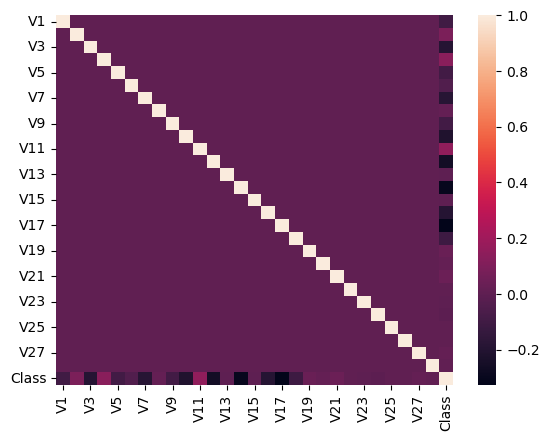

In [15]:
sns.heatmap(transaction_data.corr())
plt.show()

In [16]:
transaction_data.corr()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Class
V1,1.000000e+00,4.135835e-16,-1.227819e-15,-9.215150e-16,1.812612e-17,-6.506567e-16,-1.005191e-15,-2.433822e-16,-1.513678e-16,7.388135e-17,...,4.654551e-16,-2.457409e-16,-4.290944e-16,6.168652e-16,-4.425156e-17,-9.605737e-16,-1.581290e-17,1.198124e-16,2.083082e-15,-0.101347
V2,4.135835e-16,1.000000e+00,3.243764e-16,-1.121065e-15,5.157519e-16,2.787346e-16,2.055934e-16,-5.377041e-17,1.978488e-17,-3.991394e-16,...,2.506675e-16,-8.480447e-17,1.526333e-16,1.634231e-16,1.247925e-17,-4.478846e-16,2.057310e-16,-4.966953e-16,-5.093836e-16,0.091289
V3,-1.227819e-15,3.243764e-16,1.000000e+00,4.711293e-16,-6.539009e-17,1.627627e-15,4.895305e-16,-1.268779e-15,5.568367e-16,1.156587e-15,...,-9.316409e-16,5.706192e-17,-1.133902e-15,-4.983035e-16,2.686834e-19,-1.104734e-15,-1.238062e-16,1.045747e-15,9.775546e-16,-0.192961
V4,-9.215150e-16,-1.121065e-15,4.711293e-16,1.000000e+00,-1.719944e-15,-7.491959e-16,-4.104503e-16,5.697192e-16,6.923247e-16,2.232685e-16,...,-1.857247e-16,-1.949553e-16,-6.276051e-17,9.164206e-17,1.584638e-16,6.070716e-16,-4.247268e-16,3.977061e-17,-2.761403e-18,0.133447
V5,1.812612e-17,5.157519e-16,-6.539009e-17,-1.719944e-15,1.000000e+00,2.408382e-16,2.715541e-16,7.437229e-16,7.391702e-16,-5.202306e-16,...,-3.554057e-16,-3.920976e-16,1.253751e-16,-8.428683e-18,-1.149255e-15,4.808532e-16,4.319541e-16,6.590482e-16,-5.613951e-18,-0.094974
V6,-6.506567e-16,2.787346e-16,1.627627e-15,-7.491959e-16,2.408382e-16,1.000000e+00,1.191668e-16,-1.104219e-16,4.131207e-16,5.932243e-17,...,-1.858755e-16,5.833316e-17,-4.705235e-19,1.046712e-16,-1.071589e-15,4.562861e-16,-1.357067e-16,-4.452461e-16,2.594754e-16,-0.043643
V7,-1.005191e-15,2.055934e-16,4.895305e-16,-4.104503e-16,2.715541e-16,1.191668e-16,1.000000e+00,3.344412e-16,1.122501e-15,-7.492834e-17,...,9.379684e-16,-2.027779e-16,-8.898922e-16,-4.387401e-16,7.434913e-18,-3.094082e-16,-9.657637e-16,-1.782106e-15,-2.776530e-16,-0.187257
V8,-2.433822e-16,-5.377041e-17,-1.268779e-15,5.697192e-16,7.437229e-16,-1.104219e-16,3.344412e-16,1.000000e+00,4.356078e-16,-2.801370e-16,...,2.033737e-16,3.892798e-16,2.026927e-16,6.377260e-17,-1.047097e-16,-4.653279e-16,-1.727276e-16,1.299943e-16,-6.200930e-16,0.019875
V9,-1.513678e-16,1.978488e-17,5.568367e-16,6.923247e-16,7.391702e-16,4.131207e-16,1.122501e-15,4.356078e-16,1.000000e+00,-4.642274e-16,...,-2.343720e-16,1.936953e-16,-7.071869e-16,-5.214137e-16,-1.430343e-16,6.757763e-16,-7.888853e-16,-6.709655e-17,1.110541e-15,-0.097733
V10,7.388135e-17,-3.991394e-16,1.156587e-15,2.232685e-16,-5.202306e-16,5.932243e-17,-7.492834e-17,-2.801370e-16,-4.642274e-16,1.000000e+00,...,-1.331556e-15,1.177547e-15,-6.418202e-16,3.214491e-16,-1.355885e-16,-2.846052e-16,-3.028119e-16,-2.197977e-16,4.864782e-17,-0.216883


# 3. Анализ моделей без работы с дисбаланосом классов

Сначала построим модели без обработки дисбаланса классов, чтобы посмотреть, нужно ли будет ее проводить.

Для банка имеет большую проблему определение транзакции как нормальной, когда она мошенническая, нежели как мошеннической, когда она нормальная, потому что во втором случае можно просто договорится с клиентом и исправить ошибку, в то время как в первом, подобная промашка приведет к денежным потерям банка, которые просто так не возместить. Поэтому для оценки модели будем использовать метрику f-beta-score с приоритетом recall, которая будет отслеживать полноту определения мошеннических транзакций.

## 3.1. Построение моделей со случайными гиперпараметрами

Определим признаки и таргет в отдельные переменные

In [4]:
# Признаки
X = transaction_data.drop('Class', axis=1)
X

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28
0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,...,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053
1,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,...,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724
2,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,...,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752
3,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,...,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458
4,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,...,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,4.356170,...,-0.682920,1.475829,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731
284803,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,-0.975926,...,-1.545556,0.059616,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527
284804,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,-0.484782,...,-0.577252,0.001396,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561
284805,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,-0.399126,...,2.897849,0.127434,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533


In [5]:
# Таргет
y = transaction_data.Class
y

0         0
1         0
2         0
3         0
4         0
         ..
284802    0
284803    0
284804    0
284805    0
284806    0
Name: Class, Length: 284807, dtype: int64

Теперь разобъем данные на обучающую и тестовую выборки с помощью train_test_split из sklearn. У нас много данных, поэтому отнесем в тестовую выборку 20 процентов.

In [68]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1, shuffle=True, stratify=y)
X_train.shape, y_train.shape, X_test.shape, y_test.shape

((227845, 28), (227845,), (56962, 28), (56962,))

Подготовим модели и обучим их без работы над дисбалансом классов и выделения значимых признаков, для просморта возможного потенциала некоторых моделей. В качестве моделей были выбраны: логистическая регрессия, k-ближайших соседей, дерево решений, лес решений, Гауссовский и Бернулевский наивные Байесы и метод опорных векторов с линейным, полиномиальным и rbf ядрами. Гиперпараметры выбраны случайно также для предосмотра, но не слишком большие, чтобы модели не уходили в переобучение с большей вероятностью.

In [11]:
names = ["Log_Regeression", "Nearest_Neighbors", "Decision_Tree", "Random_Forest",
         "Gaussian_Naive_Bayes", "Bernoulli_Naive_Bayes", "Linear_SVC", "Polynomial_SVC", "RBF_SVC"]

classifiers = [
    LogisticRegression(max_iter=1000),
    KNeighborsClassifier(3),
    DecisionTreeClassifier(max_depth=6),
    RandomForestClassifier(max_depth=6, n_estimators=100),
    GaussianNB(),
    BernoulliNB(),
    LinearSVC(C=3),
    SVC(kernel="poly", C=3),
    SVC(kernel="rbf", C=3)]

In [14]:
train_scores = []
test_scores = []
fit_time = []

for name, clf in zip(names, classifiers):
    start = time.time()
    clf.fit(X_train, y_train)
    fit_time.append(time.time() - start)
    train_score = f_beta(precision_score(y_train, clf.predict(np.array(X_train))), recall_score(y_train, clf.predict(np.array(X_train))), beta=20)
    test_score = f_beta(precision_score(y_test, clf.predict(np.array(X_test))), recall_score(y_test, clf.predict(np.array(X_test))), beta=20)
    train_scores.append(train_score)
    test_scores.append(test_score)

df = pd.DataFrame()
df['name'] = names
df['train_score'] = train_scores
df['test_score'] = test_scores
df['fitting_time'] = fit_time
df.sort_values(by=["test_score"], ascending=False, inplace=True)

cm = sns.light_palette("green", as_cmap=True)
s = df.style.background_gradient(cmap=cm, subset = ['test_score'])
s

,name,train_score,test_score,fitting_time
4,Gaussian_Naive_Bayes,0.790073,0.860282,0.108194
6,Linear_SVC,0.771764,0.857165,56.749733
3,Random_Forest,0.779573,0.826783,112.031144
1,Nearest_Neighbors,0.804930,0.826699,0.062961
2,Decision_Tree,0.809983,0.816451,6.034197
8,RBF_SVC,0.848032,0.796202,153.859853
7,Polynomial_SVC,0.873373,0.796121,108.068027
0,Log_Regeression,0.596908,0.714613,2.105162
5,Bernoulli_Naive_Bayes,0.637415,0.653410,0.148972


Из выбранных моделей лучше всего себя показали Гауссовский наивный Байес и SVM с линейным ядром, у них наибольшие f-beta-score на тестовой выборке, а также отсутствует переобучение. Далее проведем диагностику моделей для потенциального подбора оптимальных гиперпараметров или границ принятий решения. Сразу уберем из рассмотрения логистическую регрессию и Бернулевский наивный Байес из-за явного сильного недообучения.

### 3.1.1. Диагностика Гауссовского наивного Байеса

Наивный Байес не обладает гиперпараметрами, но можно выбрать порог принятия решений, поэтому построим PR-кривую для отображения изменений recall и precision. Для выбора границы принятия решений воспользуемся F-beta метрикой, с таким же приоритетом recall, но другим значением beta.

In [69]:
GNB = GaussianNB().fit(X_train, y_train)

y_test_proba = GNB.predict_proba(X_test)
y_test_proba

array([[1.00000000e+00, 1.39435448e-18],
       [1.00000000e+00, 3.29095406e-17],
       [1.00000000e+00, 6.15652415e-13],
       ...,
       [9.99999999e-01, 8.22432620e-10],
       [1.00000000e+00, 6.94898962e-18],
       [1.00000000e+00, 1.05485543e-18]])

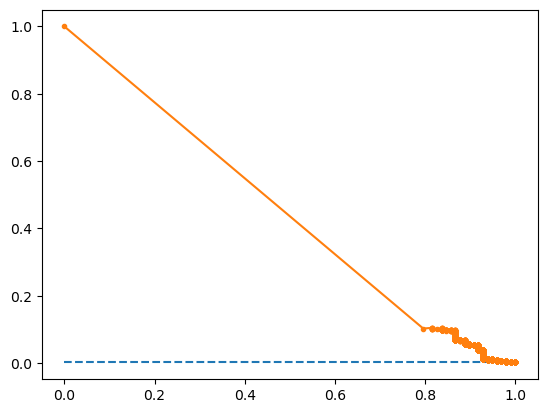

In [70]:
p, r, pr_thresholds = precision_recall_curve(y_test, y_test_proba[:, 1])
no_skill = len(y[y==1]) / len(y)
plt.plot([0, 1], [no_skill, no_skill], linestyle='--')
plt.plot(r, p, marker='.')
plt.show()

По построенному графику можно заметить, что precision принимает очень маленькие значения. Это связано с очень большим дисбалансом классов в нашем датасете, но не является большой проблемой, так как нас интересует выявление мошеннических транзакций, а не правильное определение нормальных.

Нас интересует наибольшее значение метрики, поэтому воспользуемся функцией argmax из numpy.

In [71]:
beta = 24
f_p = ((1 + beta**2) * p * r) / (beta**2 * p + r) # f-beta-score
ix = np.argmax(f_p)
print('Порог=%f, F_recall_beta-Score=%.3f' % (pr_thresholds[ix], f_p[ix]))

Порог=0.000242, F_recall_beta-Score=0.893


Отобразим выбранный порог на графике

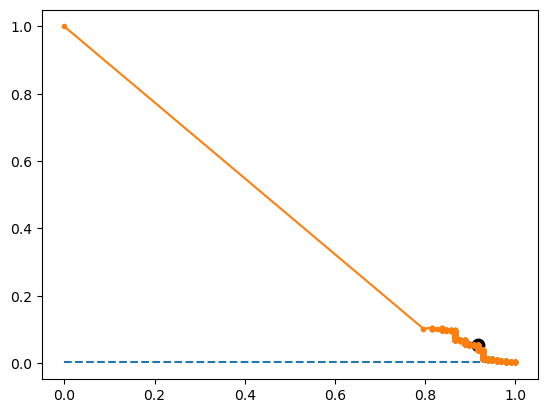

In [74]:
plt.plot([0, 1], [no_skill, no_skill], linestyle='--')
plt.plot(r, p, marker='.')
plt.scatter(r[ix], p[ix], marker='o', color='black', linewidths=4)
plt.show()

Вручную выполним классификацию с новым порогом.  

In [75]:
y_pred = (y_test_proba[:, 1] > pr_thresholds[ix]).astype('int')

Построим матрицу классов и выведим значения f-beta-score для проверки отсутствия переобучения.

In [76]:
confusion_matrix(y_train, (GNB.predict_proba(X_train)[:, 1] > pr_thresholds[ix]).astype('int'))

array([[221201,   6250],
       [    58,    336]], dtype=int64)

In [80]:
print(f'Значение f-beta-score при новой границена обучающей выборки = {f_beta(precision_score(y_train, (GNB.predict_proba(X_train)[:, 1] > pr_thresholds[ix])), recall_score(y_train, (GNB.predict_proba(X_train)[:, 1] > pr_thresholds[ix])), beta=20):.3f}')

Значение f-beta-score при новой границена обучающей выборки = 0.821


In [81]:
confusion_matrix(y_test, y_pred)

array([[55250,  1614],
       [    9,    89]], dtype=int64)

In [82]:
print(f'Значение f-beta-score при новой границена тестовой выборки = {f_p[ix]:.3f}')

Значение f-beta-score при новой границена тестовой выборки = 0.893


Переобучение отсутствует.

Хоть мы и сделали приоритетом отслеживание мошеннических транзакций, это не значит, что мы должны полностью игнорировать определение нормальных. Из матрицы можно увидеть, что нормальные транзакции определяются в большом количестве и оптимизация порога не привела к серьезным последствиям для них. Также данная матрица показывает, почему precision для мошеннических принимает такие значения, и подтверждает несерьезность таких малых величин.

### 3.1.2. Диагностика KNN

Построим график зависимости качества модели от количества соседей.

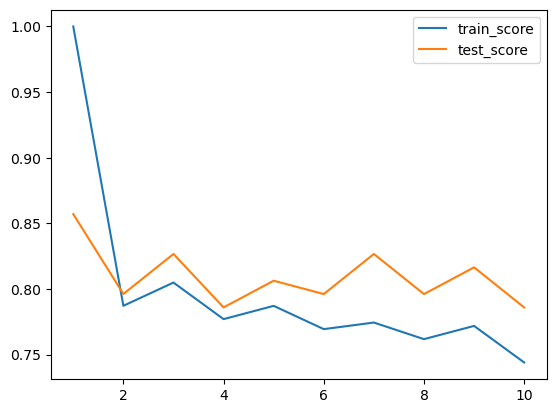

In [15]:
trains = []
tests = []
for neighbours_amount in np.arange(1, 11):
    knn = KNeighborsClassifier(neighbours_amount).fit(np.array(X_train), np.array(y_train))
    trains.append(f_beta(precision_score(y_train, knn.predict(np.array(X_train))), recall_score(y_train, knn.predict(np.array(X_train))), beta=20))
    tests.append(f_beta(precision_score(y_test, knn.predict(np.array(X_test))), recall_score(y_test, knn.predict(np.array(X_test))), beta=20))

plt.plot(np.arange(1, 11), trains, label='train_score')
plt.plot(np.arange(1, 11), tests, label='test_score')
plt.legend()
plt.show()

### 3.1.3. Диагностика дерева решений

Построим график зависимости качества модели от глубины дерева.

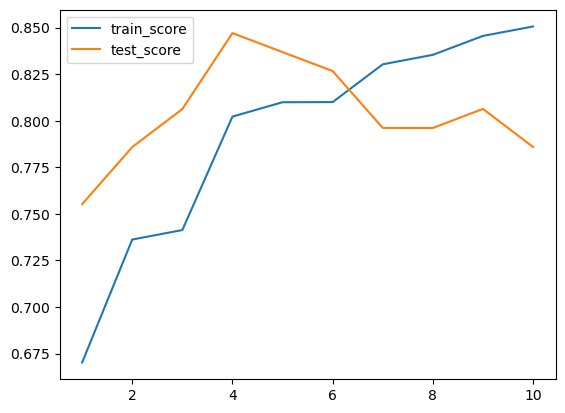

In [16]:
trains = []
tests = []
for depth in np.arange(1, 11):
    tree = DecisionTreeClassifier(max_depth=depth).fit(np.array(X_train), np.array(y_train))
    trains.append(f_beta(precision_score(y_train, tree.predict(np.array(X_train))), recall_score(y_train, tree.predict(np.array(X_train))), beta=20))
    tests.append(f_beta(precision_score(y_test, tree.predict(np.array(X_test))), recall_score(y_test, tree.predict(np.array(X_test))), beta=20))

plt.plot(np.arange(1, 11), trains, label='train_score')
plt.plot(np.arange(1, 11), tests, label='test_score')
plt.legend()
plt.show()

Из графика можно заметить хорошее дерево при глубине 4. Построим его отдельно.

In [86]:
final_tree = DecisionTreeClassifier(max_depth=4, random_state=0).fit(X_train, y_train)

print(f'train score = {f_beta(precision_score(y_train, final_tree.predict(np.array(X_train))), recall_score(y_train, final_tree.predict(np.array(X_train))), beta=20)}')
print(f'test score = {f_beta(precision_score(y_test, final_tree.predict(np.array(X_test))), recall_score(y_test, final_tree.predict(np.array(X_test))), beta=20)}')

train score = 0.8021878541177365
test score = 0.8572082962208932


### 3.1.4. Диагностика леса решений

Построим график зависимости качества модели от глубины деревьев.

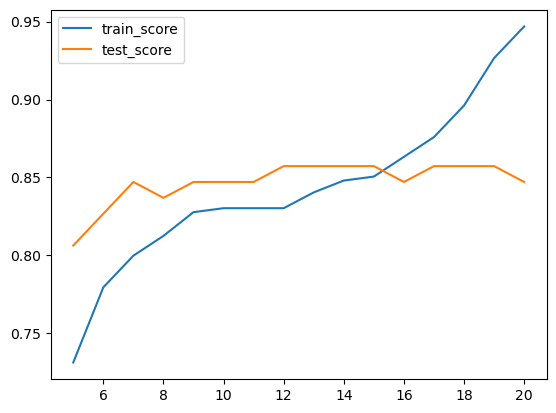

In [11]:
trains = []
tests = []
for depth in np.arange(5, 21):
    rand_tree = RandomForestClassifier(max_depth=depth, n_estimators=100, random_state=0).fit(np.array(X_train), np.array(y_train))
    trains.append(f_beta(precision_score(y_train, rand_tree.predict(np.array(X_train))), recall_score(y_train, rand_tree.predict(np.array(X_train))), beta=20))
    tests.append(f_beta(precision_score(y_test, rand_tree.predict(np.array(X_test))), recall_score(y_test, rand_tree.predict(np.array(X_test))), beta=20))

plt.plot(np.arange(5, 21), trains, label='train_score')
plt.plot(np.arange(5, 21), tests, label='test_score')
plt.legend()
plt.show()

Из графика можно заметить хороший лес при глубине 12. Построим его отдельно.

In [85]:
final_forest = RandomForestClassifier(max_depth=12, n_estimators=100, random_state=0).fit(X_train, y_train)

print(f'train score = {f_beta(precision_score(y_train, final_forest.predict(np.array(X_train))), recall_score(y_train, final_forest.predict(np.array(X_train))), beta=20)}')
print(f'test score = {f_beta(precision_score(y_test, final_forest.predict(np.array(X_test))), recall_score(y_test, final_forest.predict(np.array(X_test))), beta=20)}')

train score = 0.8303013417591671
test score = 0.8572955638695886


### 3.1.5. Диагностика полиномиального SVC

Построим график зависимости качества модели от параметра регуляризации.

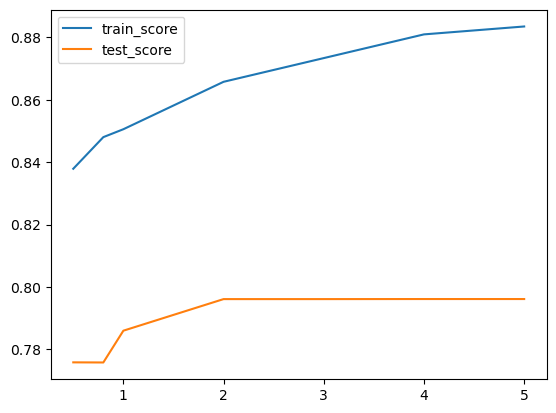

In [9]:
trains = []
tests = []
C_list = [0.5, 0.8, 1, 2, 3, 4, 5]
for c in C_list:
    svc_model = SVC(kernel='poly', C=c).fit(np.array(X_train), np.array(y_train))
    trains.append(f_beta(precision_score(y_train, svc_model.predict(np.array(X_train))), recall_score(y_train, svc_model.predict(np.array(X_train))), beta=20))
    tests.append(f_beta(precision_score(y_test, svc_model.predict(np.array(X_test))), recall_score(y_test, svc_model.predict(np.array(X_test))), beta=20))

plt.plot(C_list, trains, label='train_score')
plt.plot(C_list, tests, label='test_score')
plt.legend()
plt.show()

### 3.1.6. Диагностика rbf SVC

Построим график зависимости качества модели от параметра регуляризации.

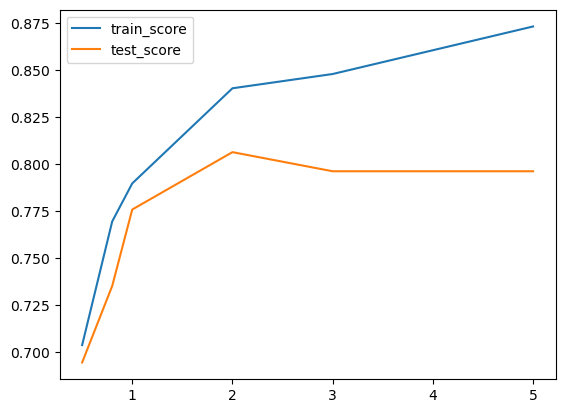

In [10]:
trains = []
tests = []
C_list = [0.5, 0.8, 1, 2, 3, 4, 5]
for c in C_list:
    svc_model = SVC(kernel='rbf', C=c).fit(np.array(X_train), np.array(y_train))
    trains.append(f_beta(precision_score(y_train, svc_model.predict(np.array(X_train))), recall_score(y_train, svc_model.predict(np.array(X_train))), beta=20))
    tests.append(f_beta(precision_score(y_test, svc_model.predict(np.array(X_test))), recall_score(y_test, svc_model.predict(np.array(X_test))), beta=20))

plt.plot(C_list, trains, label='train_score')
plt.plot(C_list, tests, label='test_score')
plt.legend()
plt.show()

### 3.1.7 Диагностика линейного SVC

Построим график зависимости качества модели от параметра регуляризации.

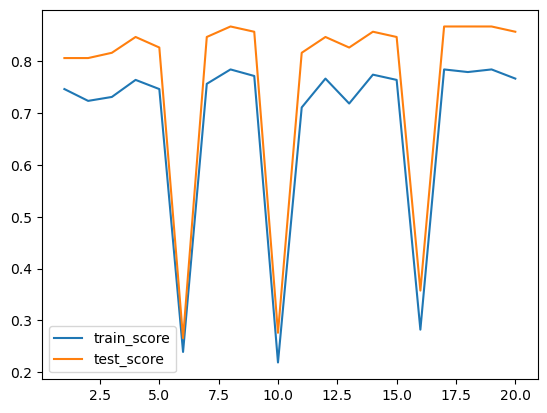

In [12]:
trains = []
tests = []
for c in np.arange(1, 21):
    svc_model = LinearSVC(C=c, random_state=0).fit(np.array(X_train), np.array(y_train))
    trains.append(f_beta(precision_score(y_train, svc_model.predict(np.array(X_train))), recall_score(y_train, svc_model.predict(np.array(X_train))), beta=20))
    tests.append(f_beta(precision_score(y_test, svc_model.predict(np.array(X_test))), recall_score(y_test, svc_model.predict(np.array(X_test))), beta=20))

plt.plot(np.arange(1, 21), trains, label='train_score')
plt.plot(np.arange(1, 21), tests, label='test_score')
plt.legend()
plt.show()

Из графика видно, что наибольшее значение метрики достигается в C = 8. Построим отдельно модель с данным значением параметра, она может пойти в вывод.

In [84]:
final_svc_model = LinearSVC(C=8, random_state=0).fit(np.array(X_train), np.array(y_train))

print(f'train score = {f_beta(precision_score(y_train, final_svc_model.predict(np.array(X_train))), recall_score(y_train, final_svc_model.predict(np.array(X_train))), beta=20)}')
print(f'test score = {f_beta(precision_score(y_test, final_svc_model.predict(np.array(X_test))), recall_score(y_test, final_svc_model.predict(np.array(X_test))), beta=20)}')

train score = 0.7843682148215201
test score = 0.8672807307702095


По окончании диагностики можно сказать, что самыми приоритетными моделями остаются Гауссовский наивный Байес и SVM с линейным ядром. Дерево и лес решений не так хороши, но набирают при определенных глубинах без переобучения относительно высокие метрики. SVM с другими ядрами переобучаются постоянно, а KNN вообще недообучается.

## 3.2. Отбор и построение признаков

Наш датасет имеет высокую вариативность (28 признаков), что может плохо сказываться на наших моделях, поэтому перед работой с дисбалансом классов проведем уменьшение размерности и посмотрим на изменение качества моделей. Также, если будет изменено количество признаков, можно это запомнить и сразу использовать в последующих пунктах.

Отбор признаков проведем через важность коэффициентов в RandomForest, так как данная модель отображает не только линейные, но и более сложные зависимости.

На основе 3.1.4 возьмем глубину 12, чтобы модель была не переобучена.

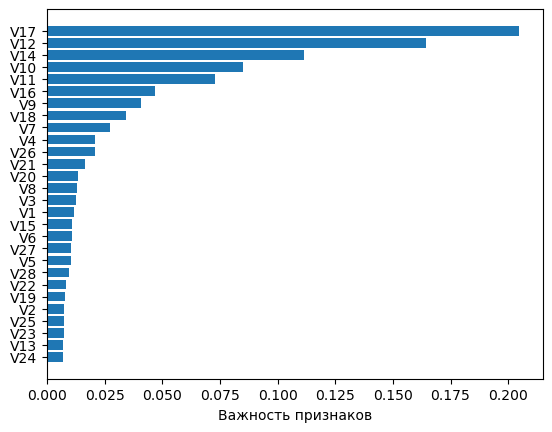

In [8]:
rf = RandomForestClassifier(max_depth=12, n_estimators=100, random_state=0).fit(X_train, y_train)

sort = rf.feature_importances_.argsort()
plt.barh(X.columns[sort], rf.feature_importances_[sort])
plt.xlabel("Важность признаков")
plt.show()

На графике видно, что после ниже атрибута V26, важность особенно маленькая. На основе этого составим список количества атрибутов, которые будем брать.

Построим модели с 23, 18, 11, 9 и 5 атрибутами

### 3.2.1 Модели с 23 атрибутами

In [15]:
trimmed_train = X_train[X_train.columns[sort][-23:]]
trimmed_test = X_test[X_test.columns[sort][-23:]]

train_scores = []
test_scores = []
fit_time = []

for name, clf in zip(names, classifiers):
    start = time.time()
    clf.fit(trimmed_train, y_train)
    fit_time.append(time.time() - start)
    train_score = f_beta(precision_score(y_train, clf.predict(np.array(trimmed_train))), recall_score(y_train, clf.predict(np.array(trimmed_train))), beta=20)
    test_score = f_beta(precision_score(y_test, clf.predict(np.array(trimmed_test))), recall_score(y_test, clf.predict(np.array(trimmed_test))), beta=20)
    train_scores.append(train_score)
    test_scores.append(test_score)

df = pd.DataFrame()
df['name'] = names
df['train_score'] = train_scores
df['test_score'] = test_scores
df['fitting_time'] = fit_time
df.sort_values(by=["test_score"], ascending=False, inplace=True)

cm = sns.light_palette("green", as_cmap=True)
s = df.style.background_gradient(cmap=cm, subset = ['test_score'])
s

,name,train_score,test_score,fitting_time
4,Gaussian_Naive_Bayes,0.799833,0.862813,0.101712
3,Random_Forest,0.774514,0.826762,69.866182
2,Decision_Tree,0.804915,0.816534,3.950045
6,Linear_SVC,0.743923,0.816493,49.142007
1,Nearest_Neighbors,0.804940,0.796202,0.029308
8,RBF_SVC,0.842965,0.796202,129.828105
7,Polynomial_SVC,0.865773,0.796141,78.716346
0,Log_Regeression,0.591835,0.714613,0.822015
5,Bernoulli_Naive_Bayes,0.627293,0.643201,0.102643


### 3.2.2. Модели с 18 атрибутами

In [14]:
trimmed_train = X_train[X_train.columns[sort][-18:]]
trimmed_test = X_test[X_test.columns[sort][-18:]]

train_scores = []
test_scores = []
fit_time = []

for name, clf in zip(names, classifiers):
    start = time.time()
    clf.fit(trimmed_train, y_train)
    fit_time.append(time.time() - start)
    train_score = f_beta(precision_score(y_train, clf.predict(np.array(trimmed_train))), recall_score(y_train, clf.predict(np.array(trimmed_train))), beta=20)
    test_score = f_beta(precision_score(y_test, clf.predict(np.array(trimmed_test))), recall_score(y_test, clf.predict(np.array(trimmed_test))), beta=20)
    train_scores.append(train_score)
    test_scores.append(test_score)

df = pd.DataFrame()
df['name'] = names
df['train_score'] = train_scores
df['test_score'] = test_scores
df['fitting_time'] = fit_time
df.sort_values(by=["test_score"], ascending=False, inplace=True)

cm = sns.light_palette("green", as_cmap=True)
s = df.style.background_gradient(cmap=cm, subset = ['test_score'])
s

,name,train_score,test_score,fitting_time
4,Gaussian_Naive_Bayes,0.825547,0.866263,0.059547
6,Linear_SVC,0.756589,0.847047,37.359385
3,Random_Forest,0.787176,0.826783,61.026280
1,Nearest_Neighbors,0.804930,0.816597,0.022170
8,RBF_SVC,0.840431,0.796222,85.422578
7,Polynomial_SVC,0.855639,0.785994,89.042423
2,Decision_Tree,0.799857,0.775787,3.219525
0,Log_Regeression,0.596923,0.694249,0.550462
5,Bernoulli_Naive_Bayes,0.568956,0.582047,0.074698


### 3.2.3. Модели с 11 атрибутами

In [15]:
trimmed_train = X_train[X_train.columns[sort][-11:]]
trimmed_test = X_test[X_test.columns[sort][-11:]]

train_scores = []
test_scores = []
fit_time = []

for name, clf in zip(names, classifiers):
    start = time.time()
    clf.fit(trimmed_train, y_train)
    fit_time.append(time.time() - start)
    train_score = f_beta(precision_score(y_train, clf.predict(np.array(trimmed_train))), recall_score(y_train, clf.predict(np.array(trimmed_train))), beta=20)
    test_score = f_beta(precision_score(y_test, clf.predict(np.array(trimmed_test))), recall_score(y_test, clf.predict(np.array(trimmed_test))), beta=20)
    train_scores.append(train_score)
    test_scores.append(test_score)

df = pd.DataFrame()
df['name'] = names
df['train_score'] = train_scores
df['test_score'] = test_scores
df['fitting_time'] = fit_time
df.sort_values(by=["test_score"], ascending=False, inplace=True)

cm = sns.light_palette("green", as_cmap=True)
s = df.style.background_gradient(cmap=cm, subset = ['test_score'])
s

,name,train_score,test_score,fitting_time
4,Gaussian_Naive_Bayes,0.830181,0.886277,0.040599
3,Random_Forest,0.794768,0.847133,45.393179
1,Nearest_Neighbors,0.815061,0.836884,0.408744
6,Linear_SVC,0.731247,0.836862,20.427608
2,Decision_Tree,0.812502,0.806369,1.872766
8,RBF_SVC,0.830291,0.775826,50.169263
7,Polynomial_SVC,0.822673,0.775648,496.775985
0,Log_Regeression,0.571525,0.673847,0.276007
5,Bernoulli_Naive_Bayes,nan,nan,0.053102


### 3.2.4. Модели с 9 атрибутами

In [16]:
trimmed_train = X_train[X_train.columns[sort][-9:]]
trimmed_test = X_test[X_test.columns[sort][-9:]]

train_scores = []
test_scores = []
fit_time = []

for name, clf in zip(names, classifiers):
    start = time.time()
    clf.fit(trimmed_train, y_train)
    fit_time.append(time.time() - start)
    train_score = f_beta(precision_score(y_train, clf.predict(np.array(trimmed_train))), recall_score(y_train, clf.predict(np.array(trimmed_train))), beta=20)
    test_score = f_beta(precision_score(y_test, clf.predict(np.array(trimmed_test))), recall_score(y_test, clf.predict(np.array(trimmed_test))), beta=20)
    train_scores.append(train_score)
    test_scores.append(test_score)

df = pd.DataFrame()
df['name'] = names
df['train_score'] = train_scores
df['test_score'] = test_scores
df['fitting_time'] = fit_time
df.sort_values(by=["test_score"], ascending=False, inplace=True)

cm = sns.light_palette("green", as_cmap=True)
s = df.style.background_gradient(cmap=cm, subset = ['test_score'])
s

,name,train_score,test_score,fitting_time
4,Gaussian_Naive_Bayes,0.829844,0.875524,0.034871
3,Random_Forest,0.809942,0.867501,46.275251
1,Nearest_Neighbors,0.809998,0.836926,0.313767
2,Decision_Tree,0.804844,0.836799,1.536005
6,Linear_SVC,0.695771,0.826699,20.005468
8,RBF_SVC,0.830291,0.786014,74.879553
7,Polynomial_SVC,0.761773,0.755371,1383.767773
0,Log_Regeression,0.566481,0.673915,0.245780
5,Bernoulli_Naive_Bayes,nan,nan,0.046772


### 3.2.5. Модели с 5 атрибутами

In [17]:
trimmed_train = X_train[X_train.columns[sort][-5:]]
trimmed_test = X_test[X_test.columns[sort][-5:]]

train_scores = []
test_scores = []
fit_time = []

for name, clf in zip(names, classifiers):
    start = time.time()
    clf.fit(trimmed_train, y_train)
    fit_time.append(time.time() - start)
    train_score = f_beta(precision_score(y_train, clf.predict(np.array(trimmed_train))), recall_score(y_train, clf.predict(np.array(trimmed_train))), beta=20)
    test_score = f_beta(precision_score(y_test, clf.predict(np.array(trimmed_test))), recall_score(y_test, clf.predict(np.array(trimmed_test))), beta=20)
    train_scores.append(train_score)
    test_scores.append(test_score)

df = pd.DataFrame()
df['name'] = names
df['train_score'] = train_scores
df['test_score'] = test_scores
df['fitting_time'] = fit_time
df.sort_values(by=["test_score"], ascending=False, inplace=True)

cm = sns.light_palette("green", as_cmap=True)
s = df.style.background_gradient(cmap=cm, subset = ['test_score'])
s

,name,train_score,test_score,fitting_time
4,Gaussian_Naive_Bayes,0.824747,0.885654,0.026372
2,Decision_Tree,0.817466,0.857165,1.001973
3,Random_Forest,0.807403,0.847068,31.686495
1,Nearest_Neighbors,0.789695,0.826720,0.188140
6,Linear_SVC,0.665354,0.796141,11.166087
8,RBF_SVC,0.807480,0.775846,454.259049
7,Polynomial_SVC,0.586814,0.704530,7834.782228
0,Log_Regeression,0.563941,0.633136,0.158454
5,Bernoulli_Naive_Bayes,nan,nan,0.035422


По проведенным обучениям можно сказать, что качество моделей хорошо повышается при 5, 9 и 11 атрибутах. При 9 признаках также наблюдается значительное уменьшение времени обучения, кроме SVC с полиномиальным ядром, и более весомый прирост качества моделей, поэтому остановимся на этом количестве.

По мимо этого, во всех случаях видно стабильное недообучение Бернулевского наивного Байеса и логистической регрессии, а также низкое качество метода опорных векторов с полиномиальным и rbf ядрами, поэтому уберем эти 4 модели из рассмотрения в целом.

In [10]:
# Обновляем X
X_new = X[X.columns[sort][-9:]]
X_new.head()

,V7,V18,V9,V16,V11,V10,V14,V12,V17
0,0.239599,0.025791,0.363787,-0.470401,-0.551600,0.090794,-0.311169,-0.617801,0.207971
1,-0.078803,-0.183361,-0.255425,0.463917,1.612727,-0.166974,-0.143772,1.065235,-0.114805
2,0.791461,-0.121359,-1.514654,-2.890083,0.624501,0.207643,-0.165946,0.066084,1.109969
3,0.237609,1.965775,-1.387024,-1.059647,-0.226487,-0.054952,-0.287924,0.178228,-0.684093
4,0.592941,-0.038195,0.817739,-0.451449,-0.822843,0.753074,-1.119670,0.538196,-0.237033


# 4. Работа с дисбалансом классов

Мы построили модели пока, никак не трогая неравномерность наличия классов в датасете. Теперь построим модели, опираясь на дисбаланс.

## 4.2. Обрезание части датасета, undersampling

Одним из вариантов борьбы с дисбалансом классов является undersampling - уменьшение количества объектов преобладающего класса и приближение его к количеству меньшего. Для применения undersampling воспользуюсь методом NearMiss из sklearn.

Очевидно, что при undersampling миноритарный класс будет находится лучше, однако теперь увеличивается ошибка поиска преобладающих объектов, поэтому в этом случае будем еще отслеживать предсказание нормальных транзакций также с помощью recall.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X_new, y, test_size=0.2, random_state=1, shuffle=True, stratify=y)
X_train.shape, y_train.shape, X_test.shape, y_test.shape

((227845, 9), (227845,), (56962, 9), (56962,))

In [29]:
# Undersampling
X_resampled, y_resampled = NearMiss().fit_resample(X_train, y_train)
X_resampled.shape, y_resampled.shape

((788, 9), (788,))

In [22]:
# Обновим набор моделей
names = ["Nearest_Neighbors", "Decision_Tree", "Random_Forest", "Gaussian_Naive_Bayes", "Linear_SVC"]

classifiers = [
    KNeighborsClassifier(3),
    DecisionTreeClassifier(max_depth=6, random_state=0),
    RandomForestClassifier(max_depth=6, n_estimators=100, random_state=0),
    GaussianNB(),
    LinearSVC(C=3, random_state=0)]

In [32]:
train_scores = []
test_scores = []
test_scores_0 = []
fit_time = []

for name, clf in zip(names, classifiers):
    start = time.time()
    clf.fit(X_resampled, y_resampled)
    fit_time.append(time.time() - start)
    train_score = f_beta(precision_score(y_resampled, clf.predict(np.array(X_resampled))), recall_score(y_resampled, clf.predict(np.array(X_resampled))), beta=20)
    test_score = f_beta(precision_score(y_test, clf.predict(np.array(X_test))), recall_score(y_test, clf.predict(np.array(X_test))), beta=20)
    train_scores.append(train_score)
    test_scores.append(test_score)
    test_scores_0.append(f_beta(precision_score(y_test, clf.predict(np.array(X_test)), pos_label=0), recall_score(y_test, clf.predict(np.array(X_test)), pos_label=0), beta=20))

df = pd.DataFrame()
df['name'] = names
df['train_score'] = train_scores
df['test_score'] = test_scores
df['test_score_for_0'] = test_scores_0
df['fitting_time'] = fit_time
df.sort_values(by=["test_score"], ascending=False, inplace=True)

cm = sns.light_palette("green", as_cmap=True)
s = df.style.background_gradient(cmap=cm, subset = ['test_score'])
s

,name,train_score,test_score,test_score_for_0,fitting_time
3,Gaussian_Naive_Bayes,0.860684,0.740451,0.843640,0.001998
4,Linear_SVC,0.880906,0.628852,0.671046,0.012509
0,Nearest_Neighbors,0.944282,0.467985,0.229849,0.002001
1,Decision_Tree,0.989860,0.442061,0.159962,0.004002
2,Random_Forest,0.982277,0.420241,0.046696,0.173657


Как и предполагалось способность модели определять мошеннические транзакции повысилась, но значительно упало определение нормальных; наилучшей предсказательной способностью обладает Гауссовский наивный Байес, да и у того только 74 процента; из-за чего делаем вывод, что в общем undersampling показал себя плохо. На самом деле это неудивительно, потому что дисбаланс классов в нашем датасете слишком большой, поэтому метод слишком уменьшал информацию об объектах преобладающего класса. Лучше использовать данный метод при меньшей неравномерности.

Никаких качественных моделей не обнаружилось, поэтому дополнительной диагностики проводить не будем и перейдем к следующему методу.

## 4.3. Добавление объектов миноритарного класса, oversampling

В данном пункте рассмотрим обратный метод - oversampling. Теперь вместо того, чтобы уменьшать количество объектов мажоритарного класса, мы будем добавлять объекты миноритарного. Аналогично NearMiss воспользуемся методом SMOTE из того же sklearn, но уже для проведения oversampling. В этот раз данных о нормальных транзакций будет достаточно, поэтому не будет такого снижения качетва, как на прошлом методе, но на всякий случай опять выведем recall для них, чтобы убедиться в этом.

### 4.3.1. Построение моделей с проведением Oversampling

In [87]:
X_train, X_test, y_train, y_test = train_test_split(X_new, y, test_size=0.2, random_state=1, shuffle=True, stratify=y)
X_train.shape, y_train.shape, X_test.shape, y_test.shape

((227845, 9), (227845,), (56962, 9), (56962,))

In [88]:
X_resampled, y_resampled = SMOTE().fit_resample(X_train, y_train)
X_resampled.shape, y_resampled.shape

((454902, 9), (454902,))

In [43]:
train_scores = []
test_scores = []
test_scores_0 = []
fit_time = []

for name, clf in zip(names, classifiers):
    start = time.time()
    clf.fit(X_resampled, y_resampled)
    fit_time.append(time.time() - start)
    train_score = f_beta(precision_score(y_resampled, clf.predict(np.array(X_resampled))), recall_score(y_resampled, clf.predict(np.array(X_resampled))), beta=20)
    test_score = f_beta(precision_score(y_test, clf.predict(np.array(X_test))), recall_score(y_test, clf.predict(np.array(X_test))), beta=20)
    train_scores.append(train_score)
    test_scores.append(test_score)
    test_scores_0.append(f_beta(precision_score(y_test, clf.predict(np.array(X_test)), pos_label=0), recall_score(y_test, clf.predict(np.array(X_test)), pos_label=0), beta=20))

df = pd.DataFrame()
df['name'] = names
df['train_score'] = train_scores
df['test_score'] = test_scores
df['test_score_for_0'] = test_scores_0
df['fitting_time'] = fit_time
df.sort_values(by=["test_score"], ascending=False, inplace=True)

cm = sns.light_palette("green", as_cmap=True)
s = df.style.background_gradient(cmap=cm, subset = ['test_score'])
s

,name,train_score,test_score,test_score_for_0,fitting_time
2,Random_Forest,0.914242,0.883500,0.980597,95.652606
4,Linear_SVC,0.875262,0.881536,0.979018,58.410669
3,Gaussian_Naive_Bayes,0.840119,0.878117,0.984246,0.088903
0,Nearest_Neighbors,0.999997,0.874325,0.997245,0.883554
1,Decision_Tree,0.925486,0.861250,0.970439,3.102328


Значения метрики для нормальных транзакций (класса 0) высоки, что подтверждает высокое качество моделей определять такие транзакции.

Значительно повысились метрики всех моделей, поэтому проведем новые диагностики.

### 4.3.2. Диагностика дерева решений

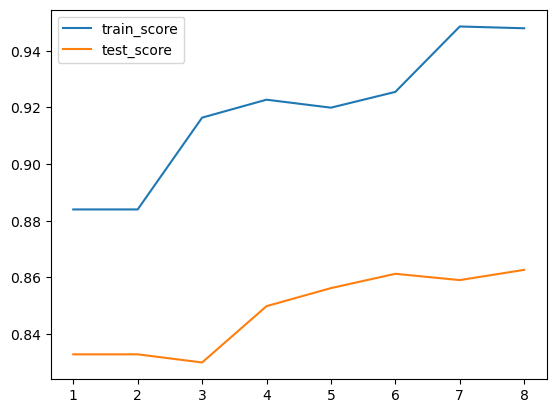

In [41]:
trains = []
tests = []

for depth in np.arange(1, 9):
    tree = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(np.array(X_resampled), np.array(y_resampled))
    trains.append(f_beta(precision_score(y_resampled, tree.predict(np.array(X_resampled))), recall_score(y_resampled, tree.predict(np.array(X_resampled))), beta=20))
    tests.append(f_beta(precision_score(y_test, tree.predict(np.array(X_test))), recall_score(y_test, tree.predict(np.array(X_test))), beta=20))

plt.plot(np.arange(1, 9), trains, label='train_score')
plt.plot(np.arange(1, 9), tests, label='test_score')
plt.legend()
plt.show()

### 4.3.3. Диагностика леса решений

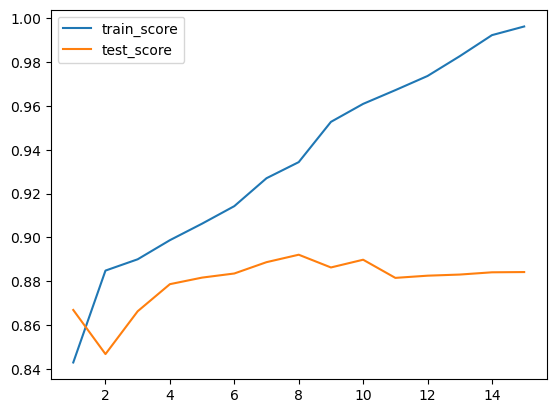

In [42]:
trains = []
tests = []

for depth in np.arange(1, 16):
    tree = RandomForestClassifier(max_depth=depth, n_estimators=100, random_state=0).fit(np.array(X_resampled), np.array(y_resampled))
    trains.append(f_beta(precision_score(y_resampled, tree.predict(np.array(X_resampled))), recall_score(y_resampled, tree.predict(np.array(X_resampled))), beta=20))
    tests.append(f_beta(precision_score(y_test, tree.predict(np.array(X_test))), recall_score(y_test, tree.predict(np.array(X_test))), beta=20))

plt.plot(np.arange(1, 16), trains, label='train_score')
plt.plot(np.arange(1, 16), tests, label='test_score')
plt.legend()
plt.show()

### 4.3.4. Диагностика Гауссовского наивного Байеса

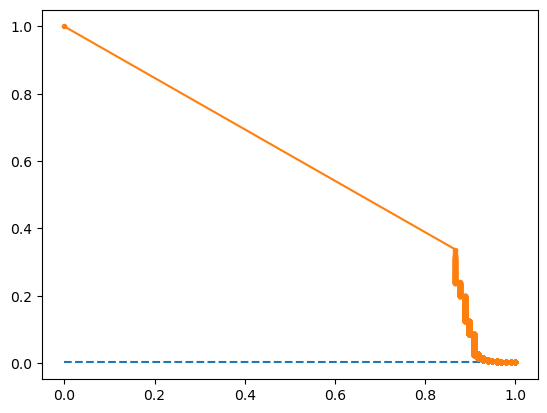

In [91]:
GNB = GaussianNB().fit(X_resampled, y_resampled)

y_test_proba = GNB.predict_proba(X_test)

p, r, pr_thresholds = precision_recall_curve(y_test, y_test_proba[:, 1])
no_skill = len(y[y==1]) / len(y)
plt.plot([0, 1], [no_skill, no_skill], linestyle='--')
plt.plot(r, p, marker='.')
plt.show()

По графику видно, что значения presicion в Гауссовском наивном Байесе после oversampling улучшились. Теперь снова поменяем порог.

In [92]:
beta = 24
f_p = ((1 + beta**2) * p * r) / (beta**2 * p + r) # f-beta-score
ix = np.argmax(f_p)
print('Порог=%f, F_recall_beta-Score=%.3f' % (pr_thresholds[ix], f_p[ix]))

Порог=0.366079, F_recall_beta-Score=0.893


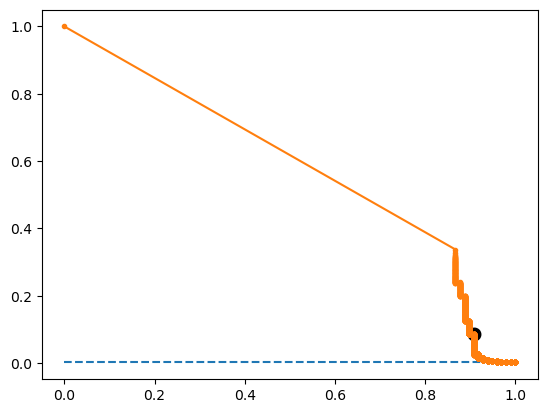

In [93]:
plt.plot([0, 1], [no_skill, no_skill], linestyle='--')
plt.plot(r, p, marker='.')
plt.scatter(r[ix], p[ix], marker='o', color='black', linewidths=4)
plt.show()

In [95]:
print(f'Значение f-beta-score при новой границена обучающей выборки = {f_beta(precision_score(y_resampled, (GNB.predict_proba(X_resampled)[:, 1] > pr_thresholds[ix])), recall_score(y_resampled, (GNB.predict_proba(X_resampled)[:, 1] > pr_thresholds[ix])), beta=24):.3f}')
print(f'Значение f-beta-score при новой границена тестовой выборки = {f_p[ix]:.3f}')

Значение f-beta-score при новой границена обучающей выборки = 0.840
Значение f-beta-score при новой границена тестовой выборки = 0.893


При том же значении beta метрика не изменилась и не переобучилась.

### 4.3.5. Диагностика KNN

Можно было заметить, что KNN очень сильно переобучился, поэтому в этот раз при диагностике воспользуемся кросс-валидацией.

In [66]:
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=15)
skf.get_n_splits(X_new, y)

3

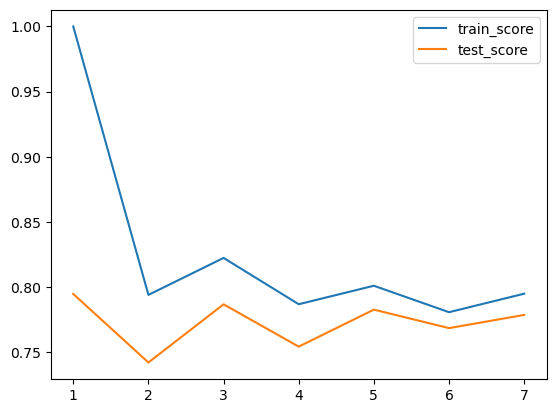

In [67]:
trains = []
tests = [] 
for neighbours_amount in np.arange(1, 8):
    
    f_beta_train_sum = 0
    f_beta_test_sum = 0
    
    knn = KNeighborsClassifier(neighbours_amount)
    cv_results = cross_validate(knn,                  
                                 X_new,                     
                                 y,                      
                                 cv = skf,                
                                 scoring = ['precision', 'recall'],
                                 return_train_score=True,
                                 n_jobs=-1)
    
    for i in range(3):
        
        f_beta_train_sum += f_beta(cv_results['train_precision'][i], cv_results['train_recall'][i], beta=20)
        f_beta_test_sum += f_beta(cv_results['test_precision'][i], cv_results['test_recall'][i], beta=20)
    
    trains.append(f_beta_train_sum / 3)
    tests.append(f_beta_test_sum / 3)
    
plt.plot(np.arange(1, 8), trains, label='train_score')
plt.plot(np.arange(1, 8), tests, label='test_score')
plt.legend()
plt.show()

### 4.3.6. Диагностика линейного SVC

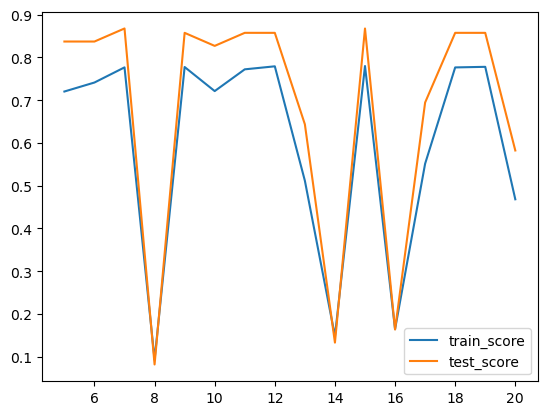

In [45]:
trains = []
tests = []
for c in np.arange(5, 21):
    svc_model = LinearSVC(C=c, random_state=0).fit(np.array(X_train), np.array(y_train))
    trains.append(f_beta(precision_score(y_resampled, svc_model.predict(np.array(X_resampled))), recall_score(y_resampled, svc_model.predict(np.array(X_resampled))), beta=20))
    tests.append(f_beta(precision_score(y_test, svc_model.predict(np.array(X_test))), recall_score(y_test, svc_model.predict(np.array(X_test))), beta=20))

plt.plot(np.arange(5, 21), trains, label='train_score')
plt.plot(np.arange(5, 21), tests, label='test_score')
plt.legend()
plt.show()

Из графика видно, что наибольшее значение метрики достигается в C = 7. Построим отдельно модель с данным значением параметра.

In [96]:
final_svc_model = LinearSVC(C=7, random_state=0).fit(np.array(X_train), np.array(y_train))

print(f'train score = {f_beta(precision_score(y_resampled, final_svc_model.predict(np.array(X_resampled))), recall_score(y_resampled, final_svc_model.predict(np.array(X_resampled))), beta=20)}')
print(f'test score = {f_beta(precision_score(y_test, final_svc_model.predict(np.array(X_test))), recall_score(y_test, final_svc_model.predict(np.array(X_test))), beta=20)}')

train score = 0.7756123239600051
test score = 0.8673910830618893


Итог: В отличии от undersampling, oversampling показал прирост предсказания мошеннических транзакций, поэтому этот метод с линейным SVM с выбранным параметром C и Гауссовским наивным Байесом с выбранным порогом можно отнести к оптимальному решению нашей задачи.

## 4.4. Придание весов классам

Последним возможным решением проблемы дисбаланса классов мы рассмотрим придание классам весов. В данном пункте переформируем набор моделей, а именно: вернем логистическую регрессию, так как качество модели может сильно возрасти благодаря весам, а также уберем из рассмотрения Гауссовского наивного Байеса из-за того, что данная модель не поддерживает веса. Оставим KNN, потому что, хоть эта модель и не поддерживает придание весов классам напрямую, у нее есть параметр, самостоятельно отвечающий за взвешивание внутри модели. В качестве тестовой и обучающей выборки опять возьмем по половине датасета.

### 4.4.1. Построение моделей с весами

In [107]:
X_train, X_test, y_train, y_test = train_test_split(X_new, y, test_size=0.2, random_state=1, shuffle=True, stratify=y)
X_train.shape, y_train.shape, X_test.shape, y_test.shape

((227845, 9), (227845,), (56962, 9), (56962,))

In [108]:
class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weights = dict(zip(np.unique(y_train), class_weights))
class_weights

{0: 0.5008661206149896, 1: 289.14340101522845}

In [48]:
# Обновим набор моделей
names = ["Log_Regeression", "Nearest_Neighbors", "Decision_Tree", "Random_Forest", "Linear_SVC"]

classifiers = [
    LogisticRegression(max_iter=1000, class_weight=class_weights),
    KNeighborsClassifier(3, weights='distance'),
    DecisionTreeClassifier(max_depth=6, class_weight=class_weights, random_state=0),
    RandomForestClassifier(max_depth=6, n_estimators=100, class_weight=class_weights, random_state=0),
    LinearSVC(C=3, class_weight=class_weights, random_state=0)]

In [49]:
train_scores = []
test_scores = []
fit_time = []

for name, clf in zip(names, classifiers):
    start = time.time()
    clf.fit(X_train, y_train)
    fit_time.append(time.time() - start)
    train_score = f_beta(precision_score(y_train, clf.predict(np.array(X_train))), recall_score(y_train, clf.predict(np.array(X_train))), beta=20)
    test_score = f_beta(precision_score(y_test, clf.predict(np.array(X_test))), recall_score(y_test, clf.predict(np.array(X_test))), beta=20)
    train_scores.append(train_score)
    test_scores.append(test_score)

df = pd.DataFrame()
df['name'] = names
df['train_score'] = train_scores
df['test_score'] = test_scores
df['fitting_time'] = fit_time
df.sort_values(by=["test_score"], ascending=False, inplace=True)

cm = sns.light_palette("green", as_cmap=True)
s = df.style.background_gradient(cmap=cm, subset = ['test_score'])
s

,name,train_score,test_score,fitting_time
3,Random_Forest,0.898127,0.894545,42.772771
0,Log_Regeression,0.849566,0.879408,0.195961
2,Decision_Tree,0.898467,0.871847,1.969607
1,Nearest_Neighbors,1.000000,0.836926,0.333318
4,Linear_SVC,0.756570,0.836862,20.470170


Построенные модели имеют высокие значения метрик, опять продигностируем их, кроме SVC.

### 4.4.2. Диагностика логистической регрессии

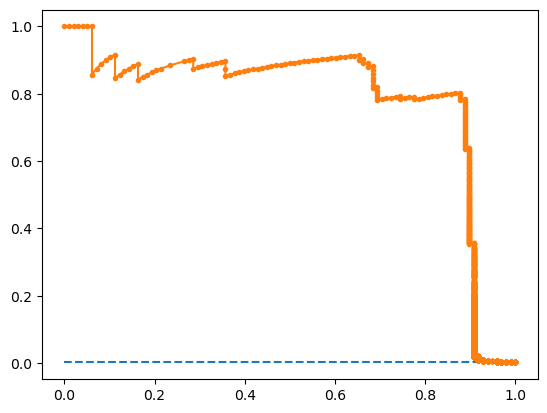

In [100]:
LogReg = LogisticRegression(max_iter=1000, class_weight=class_weights).fit(X_train, y_train)

y_test_proba = LogReg.predict_proba(X_test)

p, r, pr_thresholds = precision_recall_curve(y_test, y_test_proba[:, 1])
no_skill = len(y[y==1]) / len(y)
plt.plot([0, 1], [no_skill, no_skill], linestyle='--')
plt.plot(r, p, marker='.')
plt.show()

PR-кривая получилась весьма обнадеживающей, precision имеет высокие значения, благодаря чему модель, при смещении границы, может получиться даже лучше, чем Гауссовский наивный Байес ранее.

Снова изменим порог.

In [101]:
beta = 24
f_p = ((1 + beta**2) * p * r) / (beta**2 * p + r) # f-beta-score
ix = np.argmax(f_p)
print('Порог=%f, F_recall_beta-Score=%.3f' % (pr_thresholds[ix], f_p[ix]))

Порог=0.892179, F_recall_beta-Score=0.906


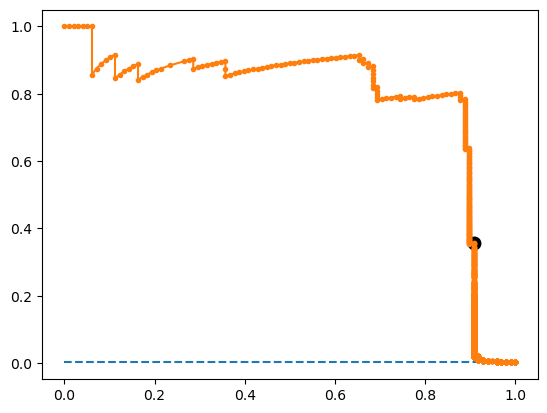

In [102]:
plt.plot([0, 1], [no_skill, no_skill], linestyle='--')
plt.plot(r, p, marker='.')
plt.scatter(r[ix], p[ix], marker='o', color='black', linewidths=4)
plt.show()

In [103]:
print(f'Значение f-beta-score при новой границе на обучающей выборки = {f_beta(precision_score(y_train, (LogReg.predict_proba(X_train)[:, 1] > pr_thresholds[ix])), recall_score(y_train, (LogReg.predict_proba(X_train)[:, 1] > pr_thresholds[ix])), beta=24):.3f}')
print(f'Значение f-beta-score при новой границе на тестовой выборки = {f_p[ix]:.3f}')

Значение f-beta-score при новой границена обучающей выборки = 0.831
Значение f-beta-score при новой границена тестовой выборки = 0.906


### 4.4.3. Диагностика дерева решений

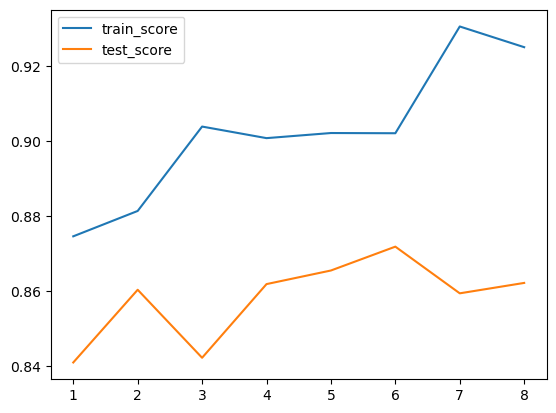

In [51]:
trains = []
tests = []

for depth in np.arange(1, 9):
    tree = DecisionTreeClassifier(max_depth=depth, class_weight=class_weights, random_state=0).fit(np.array(X_train), np.array(y_train))
    trains.append(f_beta(precision_score(y_resampled, tree.predict(np.array(X_resampled))), recall_score(y_resampled, tree.predict(np.array(X_resampled))), beta=20))
    tests.append(f_beta(precision_score(y_test, tree.predict(np.array(X_test))), recall_score(y_test, tree.predict(np.array(X_test))), beta=20))

plt.plot(np.arange(1, 9), trains, label='train_score')
plt.plot(np.arange(1, 9), tests, label='test_score')
plt.legend()
plt.show()

### 4.4.4. Диагностика леса решений

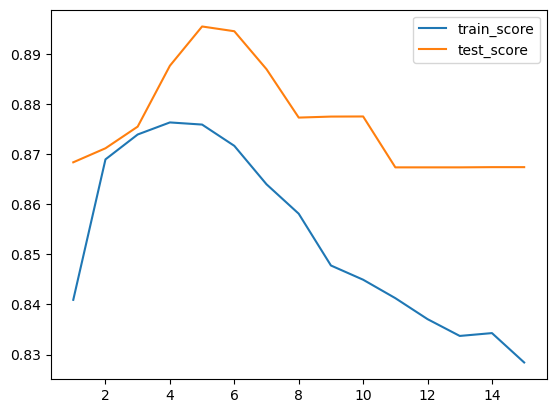

In [50]:
trains = []
tests = []

for depth in np.arange(1, 16):
    tree = RandomForestClassifier(max_depth=depth, n_estimators=100, class_weight=class_weights, random_state=0).fit(np.array(X_train), np.array(y_train))
    trains.append(f_beta(precision_score(y_resampled, tree.predict(np.array(X_resampled))), recall_score(y_resampled, tree.predict(np.array(X_resampled))), beta=20))
    tests.append(f_beta(precision_score(y_test, tree.predict(np.array(X_test))), recall_score(y_test, tree.predict(np.array(X_test))), beta=20))

plt.plot(np.arange(1, 16), trains, label='train_score')
plt.plot(np.arange(1, 16), tests, label='test_score')
plt.legend()
plt.show()

Исходя из графика в этот раз построим лес решений с глубиной 5.

In [112]:
final_forest = RandomForestClassifier(max_depth=5, n_estimators=100, class_weight=class_weights, random_state=0).fit(np.array(X_train), np.array(y_train))

print(f'train score = {f_beta(precision_score(y_train, final_forest.predict(np.array(X_train))), recall_score(y_train, final_forest.predict(np.array(X_train))), beta=20)}')
print(f'test score = {f_beta(precision_score(y_test, final_forest.predict(np.array(X_test))), recall_score(y_test, final_forest.predict(np.array(X_test))), beta=20)}')

train score = 0.8838831338316191
test score = 0.8954935514628395


### 4.4.5. Диагностика KNN

Можно было заметить, что KNN очень сильно переобучился, поэтому в этот раз при диагностике воспользуемся кросс-валидацией.

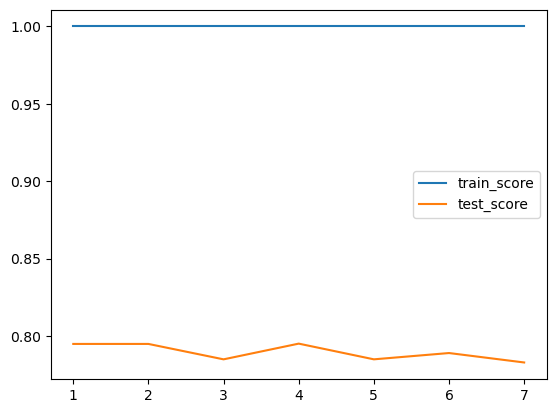

In [65]:
trains = []
tests = [] 
for neighbours_amount in np.arange(1, 8):
    
    f_beta_train_sum = 0
    f_beta_test_sum = 0
    
    knn = KNeighborsClassifier(neighbours_amount, weights='distance')
    cv_results = cross_validate(knn,                  
                                 X_new,                     
                                 y,                      
                                 cv = skf,                
                                 scoring = ['precision', 'recall'],
                                 return_train_score=True,
                                 n_jobs=-1)
    
    for i in range(3):
        
        f_beta_train_sum += f_beta(cv_results['train_precision'][i], cv_results['train_recall'][i], beta=20)
        f_beta_test_sum += f_beta(cv_results['test_precision'][i], cv_results['test_recall'][i], beta=20)
    
    trains.append(f_beta_train_sum / 3)
    tests.append(f_beta_test_sum / 3)
    
plt.plot(np.arange(1, 8), trains, label='train_score')
plt.plot(np.arange(1, 8), tests, label='test_score')
plt.legend()
plt.show()

KNN опять постоянно переобучается, поэтому перейдем к выводу.

### 4.4.6. Диагностика линейного SVC

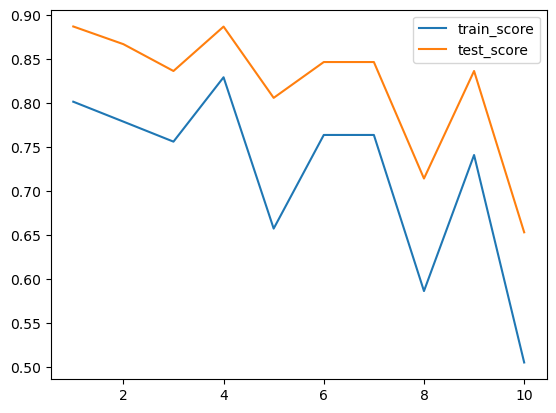

In [115]:
trains = []
tests = []
for c in np.arange(1, 11):
    svc_model = LinearSVC(C=c, class_weight=class_weights, random_state=0).fit(np.array(X_train), np.array(y_train))
    trains.append(f_beta(precision_score(y_train, svc_model.predict(np.array(X_train))), recall_score(y_train, svc_model.predict(np.array(X_train))), beta=20))
    tests.append(f_beta(precision_score(y_test, svc_model.predict(np.array(X_test))), recall_score(y_test, svc_model.predict(np.array(X_test))), beta=20))

plt.plot(np.arange(1, 11), trains, label='train_score')
plt.plot(np.arange(1, 11), tests, label='test_score')
plt.legend()
plt.show()

Из графика видно, что наибольшее значение метрики достигается в C = 1. Построим отдельно модель с данным значением параметра.

In [118]:
final_svc_model = LinearSVC(C=1, class_weight=class_weights, random_state=0).fit(np.array(X_train), np.array(y_train))

print(f'train score = {f_beta(precision_score(y_resampled, final_svc_model.predict(np.array(X_resampled))), recall_score(y_resampled, final_svc_model.predict(np.array(X_resampled))), beta=20)}')
print(f'test score = {f_beta(precision_score(y_test, final_svc_model.predict(np.array(X_test))), recall_score(y_test, final_svc_model.predict(np.array(X_test))), beta=20)}')

train score = 0.8019050227463407
test score = 0.8874615247640609


Итог: Метод с весами позволил получить еще одни уникальные решения. Из них можно взять логистическую регрессию, линейный SVM и лес решений. Несмотря на то, что мы отбросили логистическую регрессию ещё на более ранних этапах из-за явного недообучения, сейчас она показала себя как претендента на одно из оптимальнейших решений нашей задачи. Лес также достиг 89.5 поцентов метрики, что является одним из наивысших результатов. SVC тоже можно отнести к хорошей модели.

# 5. Заключение

Подведем итоги проделанной работы. Были отобраны признаки, которые повышали качетво моделей еще до рассмотрения неравномерности классов, рассмотрены различные методы по борьбе с дисбалансом, в именно: undersampling, oversampling и придание весов, - построены и получены различные модели, показывающие высокое качество на датасете и хорошо решающие поставленную задачу.

Сначала еще раз пробежимся по рассмотренным нами методам для неравномерности классов:

- Undersampling оказался самым плохим решением. Он лучше других решал задачу относительно выявления мошеннических транзакций и значительно повысил скорость обучения моделей, но настолько много потерял в предсказании нормальных, что даже с приоритетом в предсказании первых это провал. По итогу не получилось вытянуть ни одной хорошей модели.

- Oversampling оказался хорошим решением. Он повысил качества некоторых моделей: улучшил PR-кривую Гауссовского наивного Байеса, а также повысил метрику линейного SVC. Однако данный метод несет за собой увеличение данных в обучающей выборке, что серьезно может сказываться на производительности некоторых моделей, хоть такого и не наблюдалось в данной работе.

- Придание весов можно назвать лучшим решением. Он не только повысил f-beta-score и скорость обучения моделей, но и позволил получить лес решений с наивысшей метрикой и качетвенную логистическую регрессию, которая недообучалась на протяжении практически всей работы, но стала даже лучше Гауссовского наивного Байеса, который с самого начала показывал хорошие результаты.

Теперь выделим потенциально хорошие классификаторы по каждому пункту:

Модели, построенные до обработки дисбаланса и без отбора атрибутов:

- Гауссовский наивный Байес: он не переобучался, показывал хорошое предсказание нормальных транзакций даже с изменением порога и с самого начала получил метрику 86 процентов. После диагностики и смены порога f-beta-score был изменен на 89.3 процента.
- SVC с линейным ядром: не переобучался ни разу, получилось достигнуть f-beta-score 86.7 процентов, что даже чуть больше, чем у Байеса.

Модели, построенные после отбора атрибутов:

- Гауссовский наивный Байес: все то же, но еще и f-beta-score стал 87.6 процента;
- Лес решений: ушло переобучение, метрика повысилась до 86.8 процентов.

Модели, построенные после oversampling:

- SVC с линейным ядром: не переобучается, максимальный f-beta-score 86.7 процентов, как при первом построении.
- Гауссовский наивный Байес: метрика при дефолтном пороге 87.8 процента, более хорошая PR-кривая, чем при самом первом построении, что открывает больше вариативности регуляризации, при том же beta метрика стала 89.3, как при первом построении.

Модели, построенные с присвоением весов:

- Логистическая регрессия: f-beta-score при дефолтном пороге 87.9 процента; обладает гораздо более гибкой PR-кривой, чем все построенные до этого Гауссовские наивные Байесы; при смене границы f-beta-score стал 90.6 процента, что оптимальней Гауссовского наивного Байеса.
- Лес решений: максимальный с отсутсвием переобучения f-beta-score = 89.5 процентов, что лучше, по сравнению с большинством моделей, построенных до этого.
- SVC с линейным ядром: все еще ни разу не переобучился, удалось получить f-beta-score 88.7 процентов, что лучше предыдущих таких же моделей.